# 1. Setup and Imports


In [4]:
import pandas as pd
import numpy as np
import re
import string
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

# 2. Depression Dataset — Inspection


In [5]:
train_df = pd.read_csv(r"C:\Users\adivm\OneDrive\Code\Natural Language Processing\NLP Project\DataSet\depression\train.csv")
test_df = pd.read_csv(r"C:\Users\adivm\OneDrive\Code\Natural Language Processing\NLP Project\DataSet\depression\test.csv")


In [6]:
print("Training data:", train_df.shape)
print("Testing data:", test_df.shape)

print(train_df.head())
print(test_df.head())

Training data: (140000, 2)
Testing data: (60000, 2)
                                                text  label
0  bruh why can’t i have a normal dream every fuc...      0
1  my school doesn’t block facebook on the wifi b...      0
2  day 430 of recommending songs i like to r/teen...      0
3  i made it through christmashey,\n\nmy name is ...      1
4  is this a bad situation so my ex contacted me ...      0
                                                text  label
0  i'm tired of my life and i'm not sure what to ...      1
1  33, heartbroken and alone, with no future hope...      1
2  let's see what else i can cram in with two day...      0
3  day 40, ending it all anyway, nothing happened...      0
4  guys the results are here.. megathiccc is best...      0


In [7]:
print(train_df.info())
print(train_df.isnull().sum())
print(train_df["label"].value_counts())
print(train_df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140000 entries, 0 to 139999
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   text    140000 non-null  object
 1   label   140000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 2.1+ MB
None
text     0
label    0
dtype: int64
label
0    70109
1    69891
Name: count, dtype: int64
6


In [8]:
for i in range(5):
    print(f"\n--- Example {i} ---")
    print(train_df["text"].iloc[i])
    print("Label:", train_df["label"].iloc[i])

train_df["text_length"] = train_df["text"].str.len()

print(train_df["text_length"].describe())


--- Example 0 ---
bruh why can’t i have a normal dream every fucking night i’m always in this weird ass situation in a place that doesn’t exist and most of the time i end up dying like can i just have a normal dream for once instead of a nightmare every night
Label: 0

--- Example 1 ---
my school doesn’t block facebook on the wifi but it does block indeed so the teachers can go on there all they want but so help me if i wanna look for a job in my down time
Label: 0

--- Example 2 ---
day 430 of recommending songs i like to r/teenagers://youtu.be/biyl9bcp6w4

how has your day been so far?
Label: 0

--- Example 3 ---
i made it through christmashey,

my name is edmond, and i made it through another family holiday. seems normal to most, but not me. my home is usually filled with friends,and family. catching up, eating dinner, sharing stories, drinking, it was always the place to be. my parents really were good hosts.

back in 2017, my stepdad who i considered my blood father passed away f

In [9]:
train_df.groupby("label")["text_length"].describe()
train_df.groupby("label")["text_length"].mean()

label
0     327.858435
1    1173.610966
Name: text_length, dtype: float64

# 3. Text Preprocessing


In [10]:
CONTRACTIONS = {
    "i'm": "i am",
    "i've": "i have",
    "i'll": "i will",
    "i'd": "i would",

    "you're": "you are",
    "you've": "you have",
    "you'll": "you will",
    "you'd": "you would",

    "he's": "he is",
    "he'll": "he will",
    "he'd": "he would",

    "she's": "she is",
    "she'll": "she will",
    "she'd": "she would",

    "it's": "it is",
    "it'll": "it will",

    "we're": "we are",
    "we've": "we have",
    "we'll": "we will",
    "we'd": "we would",

    "they're": "they are",
    "they've": "they have",
    "they'll": "they will",
    "they'd": "they would",

    "don't": "do not",
    "doesn't": "does not",
    "didn't": "did not",

    "can't": "cannot",
    "couldn't": "could not",
    "won't": "will not",
    "wouldn't": "would not",
    "shouldn't": "should not",

    "isn't": "is not",
    "aren't": "are not",
    "wasn't": "was not",
    "weren't": "were not",

    "haven't": "have not",
    "hasn't": "has not",
    "hadn't": "had not",

    "mustn't": "must not",
    "needn't": "need not"
}

In [11]:
def expand_contractions(text):
    for contraction, expansion in CONTRACTIONS.items():
        text = text.replace(contraction, expansion)

    return text

In [12]:
def clean_text(text):

    # 1. Normalize apostrophes
    text = text.replace("’", "'").replace("‘", "'")

    # 2. Remove URLs
    text = re.sub(
        r"(https?://\S+|www\.\S+|\S+://\S+)",
        "",
        text
    )

    # 3. Convert to lowercase
    text = text.lower()

    # 4. Expand contractions
    text = expand_contractions(text)

    # 5. Remove punctuation
    text = re.sub(r"[^\w\s]", " ", text)

    # 6. Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [13]:
for i in range(5):
    print("ORIGINAL:")
    print(train_df["text"].iloc[i])

    print("\nCLEANED:")
    print(clean_text(train_df["text"].iloc[i]))

    print("\n" + "="*80)

ORIGINAL:
bruh why can’t i have a normal dream every fucking night i’m always in this weird ass situation in a place that doesn’t exist and most of the time i end up dying like can i just have a normal dream for once instead of a nightmare every night

CLEANED:
bruh why cannot i have a normal dream every fucking night i am always in this weird ass situation in a place that does not exist and most of the time i end up dying like can i just have a normal dream for once instead of a nightmare every night

ORIGINAL:
my school doesn’t block facebook on the wifi but it does block indeed so the teachers can go on there all they want but so help me if i wanna look for a job in my down time

CLEANED:
my school does not block facebook on the wifi but it does block indeed so the teachers can go on there all they want but so help me if i wanna look for a job in my down time

ORIGINAL:
day 430 of recommending songs i like to r/teenagers://youtu.be/biyl9bcp6w4

how has your day been so far?

CLEANED

In [14]:
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\adivm\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\adivm\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [15]:
nltk.download("stopwords")
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

print(len(stop_words))
print(list(stop_words)[:30])
for word in ["no", "not", "nor", "never"]:
    print(word, word in stop_words)
negation_words = {"no", "not", "nor", "never"}

stop_words = stop_words - negation_words
for word in ["no", "not", "nor", "never"]:
    print(word, word in stop_words)

198
['any', 'been', 'against', 'do', 'too', 'of', "hadn't", 'ourselves', "we'll", "they'll", "it's", 'just', "doesn't", "needn't", 'nor', 'shouldn', 'an', 'more', 'until', 'and', "couldn't", 'own', 'd', "you'll", "aren't", 'how', 'm', 'no', 'same', "shan't"]
no True
not True
nor True
never False
no False
not False
nor False
never False


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\adivm\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [16]:
tokens = ["i", "am", "not", "feeling", "very", "happy", "today"]

filtered_tokens = [
    word for word in tokens
    if word not in stop_words
]

print(filtered_tokens)

['not', 'feeling', 'happy', 'today']


In [17]:
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\adivm\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\adivm\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

# 4. Preprocessing Experiment — Lemmatization vs No Lemmatization


In [18]:
lemmatizer = WordNetLemmatizer()
words = ["cars", "studies", "running", "dogs"]

for word in words:
    print(word, "→", lemmatizer.lemmatize(word))

cars → car
studies → study
running → running
dogs → dog


In [19]:
nltk.download("averaged_perceptron_tagger")

[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\adivm\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


True

In [20]:
nltk.download("averaged_perceptron_tagger_eng")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\adivm\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\adivm\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\adivm\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [21]:

from nltk import pos_tag

tokens = ["i", "am", "feeling", "very", "sad"]

print(pos_tag(tokens))

from nltk.corpus import wordnet

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    else:
        return wordnet.NOUN

from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

lemmatizer = WordNetLemmatizer()

def lemmatize_tokens(tokens):
    pos_tags = pos_tag(tokens)

    return [
        lemmatizer.lemmatize(word, get_wordnet_pos(tag))
        for word, tag in pos_tags
    ]


tokens = ["i", "am", "feeling", "very", "sad", "cars", "running"]

lemmatized = lemmatize_tokens(tokens)

print(lemmatized)

[('i', 'NN'), ('am', 'VBP'), ('feeling', 'VBG'), ('very', 'RB'), ('sad', 'JJ')]
['i', 'be', 'feel', 'very', 'sad', 'car', 'run']


In [22]:
def preprocess_text(text):

    # Clean the text
    text = clean_text(text)

    # Tokenize
    tokens = word_tokenize(text)

    # Remove stopwords, but preserve negations
    tokens = [word for word in tokens if word not in stop_words]

    # POS-aware lemmatization
    tokens = lemmatize_tokens(tokens)

    # Convert tokens back into a single string
    return " ".join(tokens)

In [23]:
sample_df = train_df.head(100).copy()

sample_df["clean_text"] = sample_df["text"].apply(preprocess_text)

sample_df[["text", "clean_text"]].head()

,text,clean_text
0,bruh why can’t i have a normal dream every fuc...,bruh not normal dream every fucking night alwa...
1,my school doesn’t block facebook on the wifi b...,school not block facebook wifi block indeed te...
2,day 430 of recommending songs i like to r/teen...,day 430 recommend song like day far
3,"i made it through christmashey,\n\nmy name is ...",make christmashey name edmond make another fam...
4,is this a bad situation so my ex contacted me ...,bad situation ex contact talk lot recently wee...


In [24]:
import time

start = time.time()

sample_df = train_df.head(100).copy()
sample_df["clean_text"] = sample_df["text"].apply(preprocess_text)

end = time.time()

print("Time taken:", end - start, "seconds")

Time taken: 0.2815859317779541 seconds


In [25]:
sample_df["clean_text"]
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(sample_df["clean_text"])
print(X_tfidf.shape)
print(tfidf.get_feature_names_out()[:20])

(100, 2027)
['00' '10' '100' '11' '12' '12th' '13' '16' '17' '18' '19' '1965' '20'
 '2016' '2017' '2018' '2019' '21p' '22' '23']


In [26]:
print(X_tfidf[0])
print(X_tfidf[0].toarray())

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 19 stored elements and shape (1, 2027)>
  Coords	Values
  (0, 259)	0.23204486441145974
  (0, 1222)	0.14804124516155423
  (0, 1220)	0.3770264014926405
  (0, 546)	0.39286601554507355
  (0, 610)	0.298713387940887
  (0, 730)	0.1756014070577091
  (0, 1206)	0.363305503696883
  (0, 100)	0.16082115113361384
  (0, 1956)	0.21726460848736448
  (0, 149)	0.18851320074632025
  (0, 1612)	0.19643300777253678
  (0, 1336)	0.1529013441073973
  (0, 626)	0.20580015132419413
  (0, 1816)	0.11206019299863194
  (0, 585)	0.1529013441073973
  (0, 498)	0.14604089520951855
  (0, 1018)	0.09645788675364668
  (0, 927)	0.20580015132419413
  (0, 1207)	0.23204486441145974
[[0. 0. 0. ... 0. 0. 0.]]


In [27]:
def preprocess_without_lemmatization(text):

    # Cleaning
    text = clean_text(text)

    # Tokenization
    tokens = word_tokenize(text)

    # Stopword removal
    tokens = [word for word in tokens if word not in stop_words]

    # Convert back to text
    return " ".join(tokens)
    

In [28]:
sample_df["without_lemma"] = sample_df["text"].apply(
    preprocess_without_lemmatization
)

sample_df["with_lemma"] = sample_df["text"].apply(
    preprocess_text
)

print(sample_df[["without_lemma", "with_lemma"]].head())

                                       without_lemma  \
0  bruh not normal dream every fucking night alwa...   
1  school not block facebook wifi block indeed te...   
2            day 430 recommending songs like day far   
3  made christmashey name edmond made another fam...   
4  bad situation ex contacted talking lot recentl...   

                                          with_lemma  
0  bruh not normal dream every fucking night alwa...  
1  school not block facebook wifi block indeed te...  
2                day 430 recommend song like day far  
3  make christmashey name edmond make another fam...  
4  bad situation ex contact talk lot recently wee...  


In [29]:
tfidf_without = TfidfVectorizer()

X_without = tfidf_without.fit_transform(
    sample_df["without_lemma"]
)

tfidf_with = TfidfVectorizer()

X_with = tfidf_with.fit_transform(
    sample_df["with_lemma"]
)

print("Without lemmatization:", X_without.shape)
print("With lemmatization:", X_with.shape)

Without lemmatization: (100, 2384)
With lemmatization: (100, 2027)


# 6. Depression Classification — Model Comparison


In [30]:
from sklearn.linear_model import LogisticRegression

y_sample = train_df["label"].head(100)

print(y_sample.value_counts())

label
1    54
0    46
Name: count, dtype: int64


In [31]:
model_without = LogisticRegression(max_iter=1000)

model_without.fit(X_without, y_sample)

pred_without = model_without.predict(X_without)

model_with = LogisticRegression(max_iter=1000)

model_with.fit(X_with, y_sample)

pred_with = model_with.predict(X_with)
from sklearn.metrics import accuracy_score

print("Without lemmatization:",
      accuracy_score(y_sample, pred_without))

print("With lemmatization:",
      accuracy_score(y_sample, pred_with))

Without lemmatization: 0.99
With lemmatization: 0.99


# 5. Depression Classification — Train / Validation


In [32]:
from sklearn.model_selection import train_test_split

X_train_text, X_val_text, y_train, y_val = train_test_split(
    train_df["text"],
    train_df["label"],
    test_size=0.2,
    random_state=42,
    stratify=train_df["label"]
)
print(X_train_text.shape)
print(X_val_text.shape)

print(y_train.value_counts())
print(y_val.value_counts())

(112000,)
(28000,)
label
0    56087
1    55913
Name: count, dtype: int64
label
0    14022
1    13978
Name: count, dtype: int64


In [33]:
X_train_clean = X_train_text.apply(
    preprocess_without_lemmatization
)

X_val_clean = X_val_text.apply(
    preprocess_without_lemmatization
)

tfidf_without = TfidfVectorizer()

X_train_tfidf = tfidf_without.fit_transform(X_train_clean)

X_val_tfidf = tfidf_without.transform(X_val_clean)


In [34]:
print(X_train_tfidf.shape)
print(X_val_tfidf.shape)

(112000, 110254)
(28000, 110254)


In [35]:
from sklearn.linear_model import LogisticRegression
model_without = LogisticRegression(
    max_iter=1000
)

model_without.fit(
    X_train_tfidf,
    y_train
)
y_pred_without = model_without.predict(X_val_tfidf)
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:",
      accuracy_score(y_val, y_pred_without))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_without))


Accuracy: 0.9246785714285715

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.93      0.93     14022
           1       0.93      0.92      0.92     13978

    accuracy                           0.92     28000
   macro avg       0.92      0.92      0.92     28000
weighted avg       0.92      0.92      0.92     28000



In [37]:
import pandas as pd

X_train_lemma = pd.read_csv(
    r"C:\Users\adivm\OneDrive\Code\Natural Language Processing\NLP Project\DataSet\depression\X_train_lemma.csv"
).iloc[:, 0]

X_val_lemma = pd.read_csv(
    r"C:\Users\adivm\OneDrive\Code\Natural Language Processing\NLP Project\DataSet\depression\X_val_lemma.csv"
).iloc[:, 0]

In [38]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_lemma = TfidfVectorizer()

X_train_tfidf_lemma = tfidf_lemma.fit_transform(X_train_lemma)
X_val_tfidf_lemma = tfidf_lemma.transform(X_val_lemma)

print("Training shape:", X_train_tfidf_lemma.shape)
print("Validation shape:", X_val_tfidf_lemma.shape)

ValueError: np.nan is an invalid document, expected byte or unicode string.

In [39]:
from sklearn.linear_model import LogisticRegression

model_lemma = LogisticRegression(max_iter=1000)

model_lemma.fit(
    X_train_tfidf_lemma,
    y_train
)
y_pred_lemma = model_lemma.predict(X_val_tfidf_lemma)
from sklearn.metrics import accuracy_score, classification_report

print(
    "Accuracy:",
    accuracy_score(y_val, y_pred_lemma)
)

print("\nClassification Report:")
print(classification_report(y_val, y_pred_lemma))

NameError: name 'X_train_tfidf_lemma' is not defined

In [40]:
from sklearn.naive_bayes import MultinomialNB

model_nb = MultinomialNB()

model_nb.fit(
    X_train_tfidf,
    y_train
)

y_pred_nb = model_nb.predict(X_val_tfidf)

from sklearn.metrics import accuracy_score, classification_report

print(
    "Accuracy:",
    accuracy_score(y_val, y_pred_nb)
)

print("\nClassification Report:")
print(classification_report(y_val, y_pred_nb))

Accuracy: 0.8750357142857143

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.77      0.86     14022
           1       0.81      0.98      0.89     13978

    accuracy                           0.88     28000
   macro avg       0.89      0.88      0.87     28000
weighted avg       0.89      0.88      0.87     28000



In [41]:
from sklearn.svm import LinearSVC

model_svm = LinearSVC()

model_svm.fit(
    X_train_tfidf,
    y_train
)

y_pred_svm = model_svm.predict(X_val_tfidf)
print(
    "Accuracy:",
    accuracy_score(y_val, y_pred_svm)
)

print("\nClassification Report:")
print(classification_report(y_val, y_pred_svm))

Accuracy: 0.927

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.94      0.93     14022
           1       0.93      0.92      0.93     13978

    accuracy                           0.93     28000
   macro avg       0.93      0.93      0.93     28000
weighted avg       0.93      0.93      0.93     28000



# 7. Depression Classification — Final Test Evaluation


In [42]:
test_text = test_df["text"]
X_test_clean = test_text.apply(preprocess_without_lemmatization)
X_test_tfidf = tfidf_without.transform(X_test_clean)
y_test = test_df["label"]
y_pred_test = model_svm.predict(X_test_tfidf)

In [43]:
from sklearn.metrics import accuracy_score, classification_report

print(
    "Test Accuracy:",
    accuracy_score(y_test, y_pred_test)
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_test))

Test Accuracy: 0.9269666666666667

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.94      0.93     29891
           1       0.94      0.92      0.93     30109

    accuracy                           0.93     60000
   macro avg       0.93      0.93      0.93     60000
weighted avg       0.93      0.93      0.93     60000



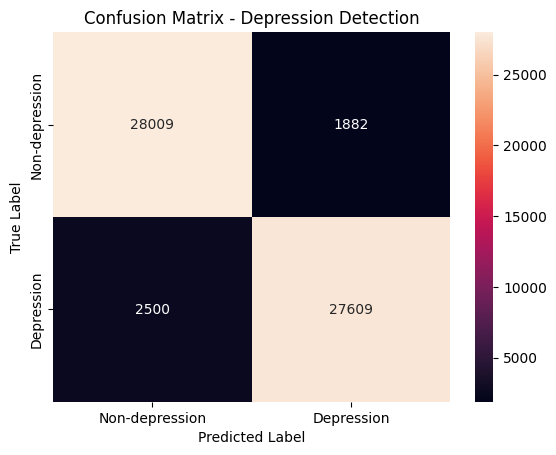

In [44]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_test)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Non-depression", "Depression"],
    yticklabels=["Non-depression", "Depression"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Depression Detection")
plt.show()

# 8. Emotion Dataset — Inspection


In [46]:
from datasets import load_dataset

emotion_dataset = load_dataset("dair-ai/emotion")

print(emotion_dataset)
print(emotion_dataset["train"][0])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})
{'text': 'i didnt feel humiliated', 'label': 0}


In [48]:
train_emotion = emotion_dataset["train"].to_pandas()
val_emotion = emotion_dataset["validation"].to_pandas()
test_emotion = emotion_dataset["test"].to_pandas()
print(train_emotion.shape)
print(val_emotion.shape)
print(test_emotion.shape)
print(train_emotion["label"].value_counts().sort_index())

(16000, 2)
(2000, 2)
(2000, 2)
label
0    4666
1    5362
2    1304
3    2159
4    1937
5     572
Name: count, dtype: int64


In [49]:
print(train_emotion.head(10))
print(train_emotion["text"].iloc[0])
print(train_emotion["label"].iloc[0])
print(train_emotion.isnull().sum())

                                                text  label
0                            i didnt feel humiliated      0
1  i can go from feeling so hopeless to so damned...      0
2   im grabbing a minute to post i feel greedy wrong      3
3  i am ever feeling nostalgic about the fireplac...      2
4                               i am feeling grouchy      3
5  ive been feeling a little burdened lately wasn...      0
6  ive been taking or milligrams or times recomme...      5
7  i feel as confused about life as a teenager or...      4
8  i have been with petronas for years i feel tha...      1
9                                i feel romantic too      2
i didnt feel humiliated
0
text     0
label    0
dtype: int64


In [50]:
print("Duplicate rows:", train_emotion.duplicated().sum())
print(
    "Duplicate texts:",
    train_emotion["text"].duplicated().sum()
)
print("Train:")
print(train_emotion["label"].value_counts().sort_index())

print("\nValidation:")
print(val_emotion["label"].value_counts().sort_index())

print("\nTest:")
print(test_emotion["label"].value_counts().sort_index())

Duplicate rows: 1
Duplicate texts: 31
Train:
label
0    4666
1    5362
2    1304
3    2159
4    1937
5     572
Name: count, dtype: int64

Validation:
label
0    550
1    704
2    178
3    275
4    212
5     81
Name: count, dtype: int64

Test:
label
0    581
1    695
2    159
3    275
4    224
5     66
Name: count, dtype: int64


# 9. Emotion Classification — Preprocessing and TF-IDF


In [52]:
import time

start = time.time()

X_train_emotion = train_emotion["text"].apply(
    preprocess_without_lemmatization
)

print(
    "Training preprocessing time:",
    time.time() - start,
    "seconds"
)
start = time.time()

X_val_emotion = val_emotion["text"].apply(
    preprocess_without_lemmatization
)

print(
    "Validation preprocessing time:",
    time.time() - start,
    "seconds"
)
start = time.time()

X_test_emotion = test_emotion["text"].apply(
    preprocess_without_lemmatization
)

print(
    "Test preprocessing time:",
    time.time() - start,
    "seconds"
)

Training preprocessing time: 0.8412916660308838 seconds
Validation preprocessing time: 0.10260319709777832 seconds
Test preprocessing time: 0.10531353950500488 seconds


In [54]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_emotion = TfidfVectorizer()
X_train_emotion_tfidf = tfidf_emotion.fit_transform(
    X_train_emotion
)
X_val_emotion_tfidf = tfidf_emotion.transform(
    X_val_emotion
)

X_test_emotion_tfidf = tfidf_emotion.transform(
    X_test_emotion
)
print("Training:", X_train_emotion_tfidf.shape)
print("Validation:", X_val_emotion_tfidf.shape)
print("Test:", X_test_emotion_tfidf.shape)


Training: (16000, 15047)
Validation: (2000, 15047)
Test: (2000, 15047)


# 10. Emotion Classification — Model Comparison


In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# -----------------------------
# 1. Logistic Regression
# -----------------------------

model_lr_emotion = LogisticRegression(
    max_iter=1000
)

model_lr_emotion.fit(
    X_train_emotion_tfidf,
    train_emotion["label"]
)

y_val_pred_lr = model_lr_emotion.predict(
    X_val_emotion_tfidf
)

print("Logistic Regression")
print(
    "Accuracy:",
    accuracy_score(
        val_emotion["label"],
        y_val_pred_lr
    )
)

print("\nClassification Report:")
print(
    classification_report(
        val_emotion["label"],
        y_val_pred_lr
    )
)

Logistic Regression
Accuracy: 0.8745

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.94      0.91       550
           1       0.86      0.95      0.90       704
           2       0.90      0.71      0.79       178
           3       0.90      0.84      0.87       275
           4       0.87      0.75      0.81       212
           5       0.87      0.59      0.71        81

    accuracy                           0.87      2000
   macro avg       0.88      0.80      0.83      2000
weighted avg       0.88      0.87      0.87      2000



In [56]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# 1. Create model
model_nb_emotion = MultinomialNB()

# 2. Train
model_nb_emotion.fit(
    X_train_emotion_tfidf,
    train_emotion["label"]
)

# 3. Predict validation data
y_val_pred_nb = model_nb_emotion.predict(
    X_val_emotion_tfidf
)

# 4. Evaluate
print("Multinomial Naive Bayes")
print(
    "Accuracy:",
    accuracy_score(
        val_emotion["label"],
        y_val_pred_nb
    )
)

print("\nClassification Report:")
print(
    classification_report(
        val_emotion["label"],
        y_val_pred_nb
    )
)

Multinomial Naive Bayes
Accuracy: 0.6755

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.94      0.77       550
           1       0.65      0.98      0.78       704
           2       1.00      0.05      0.10       178
           3       0.98      0.31      0.47       275
           4       0.94      0.24      0.38       212
           5       1.00      0.01      0.02        81

    accuracy                           0.68      2000
   macro avg       0.87      0.42      0.42      2000
weighted avg       0.77      0.68      0.60      2000



In [57]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# 1. Create Linear SVM model
model_svm_emotion = LinearSVC()

# 2. Train
model_svm_emotion.fit(
    X_train_emotion_tfidf,
    train_emotion["label"]
)

# 3. Predict validation data
y_val_pred_svm = model_svm_emotion.predict(
    X_val_emotion_tfidf
)

# 4. Evaluate
print("Linear SVM")
print(
    "Accuracy:",
    accuracy_score(
        val_emotion["label"],
        y_val_pred_svm
    )
)

print("\nClassification Report:")
print(
    classification_report(
        val_emotion["label"],
        y_val_pred_svm
    )
)

Linear SVM
Accuracy: 0.903

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.93      0.92       550
           1       0.91      0.93      0.92       704
           2       0.86      0.83      0.84       178
           3       0.92      0.91      0.91       275
           4       0.87      0.82      0.85       212
           5       0.83      0.79      0.81        81

    accuracy                           0.90      2000
   macro avg       0.88      0.87      0.88      2000
weighted avg       0.90      0.90      0.90      2000



# 11. Emotion Classification — Final Test Evaluation


In [58]:
from sklearn.metrics import accuracy_score, classification_report

# 1. Predict the untouched test set
y_test_pred_svm = model_svm_emotion.predict(
    X_test_emotion_tfidf
)

# 2. Evaluate final test performance
print("Linear SVM - Final Test Results")

print(
    "Test Accuracy:",
    accuracy_score(
        test_emotion["label"],
        y_test_pred_svm
    )
)

print("\nClassification Report:")
print(
    classification_report(
        test_emotion["label"],
        y_test_pred_svm
    )
)


Linear SVM - Final Test Results
Test Accuracy: 0.8915

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       581
           1       0.90      0.93      0.91       695
           2       0.78      0.77      0.78       159
           3       0.88      0.88      0.88       275
           4       0.87      0.85      0.86       224
           5       0.80      0.68      0.74        66

    accuracy                           0.89      2000
   macro avg       0.86      0.84      0.85      2000
weighted avg       0.89      0.89      0.89      2000



# 12. Final Confusion Matrices


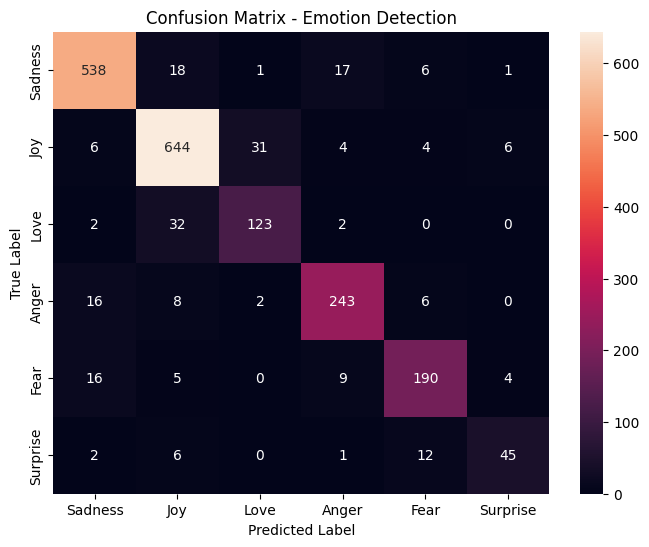

In [59]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_emotion = confusion_matrix(
    test_emotion["label"],
    y_test_pred_svm
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_emotion,
    annot=True,
    fmt="d",
    xticklabels=[
        "Sadness",
        "Joy",
        "Love",
        "Anger",
        "Fear",
        "Surprise"
    ],
    yticklabels=[
        "Sadness",
        "Joy",
        "Love",
        "Anger",
        "Fear",
        "Surprise"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Emotion Detection")
plt.show()

# 13. Save Models for Deployment


In [60]:
import joblib
import joblib

# Save Emotion model
joblib.dump(
    model_svm_emotion,
    r"C:\Users\adivm\OneDrive\Code\Natural Language Processing\NLP Project\models\emotion_model.joblib"
)

# Save Emotion TF-IDF vectorizer
joblib.dump(
    tfidf_emotion,
    r"C:\Users\adivm\OneDrive\Code\Natural Language Processing\NLP Project\models\emotion_tfidf.joblib"
)

# Save Depression model
joblib.dump(
    model_svm,
    r"C:\Users\adivm\OneDrive\Code\Natural Language Processing\NLP Project\models\depression_model.joblib"
)

# Save Depression TF-IDF vectorizer
joblib.dump(
    tfidf_without,
     r"C:\Users\adivm\OneDrive\Code\Natural Language Processing\NLP Project\models\depression_tfidf.joblib"
)

print("All models and vectorizers saved successfully.")

All models and vectorizers saved successfully.


In [62]:
import joblib

emotion_model = joblib.load("../models/emotion_model.joblib")
emotion_tfidf = joblib.load("../models/emotion_tfidf.joblib")

depression_model = joblib.load("../models/depression_model.joblib")
depression_tfidf = joblib.load("../models/depression_tfidf.joblib")

print("All models and vectorizers loaded successfully!")

All models and vectorizers loaded successfully!
